# Analiza sentymentu i walencji dramatu *Wesele* · wersja 0.1

Prototyp wzorowany na części 3 laboratorium *Analiza sentymentu* (`exercise-3` i `inspect-section`), dostosowany do języka polskiego i struktury dramatu Stanisława Wyspiańskiego (`wesele.epub`).

**Co robi wersja 0.1:**
1. Wydobywa czyste kwestie z `EPUB/part2.xhtml`–`EPUB/part4.xhtml` (Akt I–III), pomijając spis osób, przypisy i opcjonalnie didaskalia.
2. Lematyzuje tekst za pomocą `spaCy` (`pl_core_news_sm`), aby dopasować odmienione wyrazy do form podstawowych.
3. Łączy lematy ze słownikiem **ANPW_R** (*Affective Norms for 4900 Polish Words Reload*, Imbir 2016) w skali walencji 1–9 (oraz pomocniczo w progach pozytywne/negatywne).
4. Rysuje przebieg walencji / bilansu na 1000 słów w kolejnych blokach tekstu wraz z wykresem pokrycia słownika i podglądem wybranych fragmentów.

In [1]:
#@title 1. Przygotuj biblioteki i model spaCy
import importlib.util
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

packages = ("beautifulsoup4", "lxml", "openpyxl", "pandas", "matplotlib", "requests", "spacy")
missing = []
for pkg in packages:
    try:
        version(pkg)
    except PackageNotFoundError:
        missing.append(pkg)

if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-qq", "--disable-pip-version-check", *missing])

import spacy
if not spacy.util.is_package("pl_core_news_sm"):
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "pl_core_news_sm"])

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 80)
print("Środowisko gotowe.", {"spacy": version("spacy"), "pandas": version("pandas")})

Środowisko gotowe. {'spacy': '3.8.18', 'pandas': '3.1.1'}


In [2]:
#@title 2. Wczytaj i sparsuj tekst dramatu z wesele.epub
import zipfile
from pathlib import Path
from bs4 import BeautifulSoup

epub_path = "wesele.epub" #@param {type:"string"}
include_didaskalia = False #@param {type:"boolean"}

if not Path(epub_path).is_file():
    try:
        from google.colab import files
        print("Wgraj plik wesele.epub:")
        uploaded = files.upload()
        epub_path = next(iter(uploaded))
    except ImportError as exc:
        raise FileNotFoundError(f"Nie znaleziono pliku {epub_path} w bieżącym katalogu.") from exc


def parse_wesele_epub(path: str, keep_didaskalia: bool = False) -> pd.DataFrame:
    """Extract speeches (and optionally stage directions) from Acts I-III of Wolne Lektury EPUB."""
    act_files = ["EPUB/part2.xhtml", "EPUB/part3.xhtml", "EPUB/part4.xhtml"]
    records = []
    with zipfile.ZipFile(path) as archive:
        for part in act_files:
            soup = BeautifulSoup(archive.read(part), "lxml-xml")
            # Remove footnote anchors so numbers like '20' do not glue onto words.
            for anchor in soup.select("a.anchor"):
                anchor.decompose()

            book_root = soup.select_one("#book-text")
            current_act = ""
            current_scene = ""
            current_speaker = ""

            for node in book_root.find_all(["h2", "div"], recursive=False):
                classes = node.get("class", [])
                if node.name == "h2":
                    text = node.get_text(" ", strip=True)
                    if "h2" in classes:
                        current_act = text
                    elif "h3" in classes:
                        current_scene = text
                    elif "h4" in classes:
                        current_speaker = text
                elif node.name == "div":
                    if "didaskalia" in classes and keep_didaskalia:
                        text = node.get_text(" ", strip=True)
                        if text:
                            records.append({
                                "act": current_act, "scene": current_scene,
                                "speaker": "[DIDASKALIA]", "kind": "didaskalia", "text": text,
                            })
                    elif "kwestia" in classes:
                        if not keep_didaskalia:
                            for nested in node.select(".didaskalia"):
                                nested.decompose()
                        verses = [v.get_text(" ", strip=True) for v in node.select("div.verse")]
                        text = " ".join(v for v in verses if v)
                        if text:
                            records.append({
                                "act": current_act, "scene": current_scene,
                                "speaker": current_speaker, "kind": "kwestia", "text": text,
                            })
    return pd.DataFrame(records)


speeches_df = parse_wesele_epub(epub_path, keep_didaskalia=include_didaskalia)
print(f"Wczytano fragmentów: {len(speeches_df)} (include_didaskalia={include_didaskalia})")
display(speeches_df.groupby("act", sort=False).agg(fragmenty=("text", "size"), sceny=("scene", "nunique")))
display(speeches_df.head(5))

Wczytano fragmentów: 1506 (include_didaskalia=False)


,fragmenty,sceny
act,,
AKT I,507,38
AKT II,519,30
AKT III,480,36


,act,scene,speaker,kind,text
0,AKT I,SCENA I,CZEPIEC,kwestia,"Cóz tam, panie, w polityce? Chińcyki trzymają się mocno!?"
1,AKT I,SCENA I,DZIENNIKARZ,kwestia,"A, mój miły gospodarzu, mam przez cały dzień dosyć Chińczyków."
2,AKT I,SCENA I,CZEPIEC,kwestia,Pan polityk!
3,AKT I,SCENA I,DZIENNIKARZ,kwestia,"Otóż właśnie polityków mam dość, po uszy, dzień cały."
4,AKT I,SCENA I,CZEPIEC,kwestia,Kiedy to ciekawe sprawy.


In [3]:
#@title 3. Pobierz i przygotuj słownik walencji (ANPW_R lub własny CSV)
import requests

lexicon_path = "anpwr.xlsx" #@param {type:"string"}
custom_lexicon_csv = "" #@param {type:"string"}
neg_threshold = 4.0 #@param {type:"number"}
pos_threshold = 6.0 #@param {type:"number"}

ANPWR_URL = "https://ndownloader.figshare.com/files/30426825"


def load_lexicon(
    xlsx_path: str = "anpwr.xlsx",
    custom_csv: str = "",
    neg_cut: float = 4.0,
    pos_cut: float = 6.0,
) -> pd.DataFrame:
    """Load ANPW_R (or a custom CSV with 'word' and 'valence') and normalize columns."""
    if custom_csv.strip():
        raw = pd.read_csv(custom_csv.strip())
        table = raw.rename(columns=str.lower)[["word", "valence"]].copy()
        if "arousal" in raw.columns:
            table["arousal"] = raw["arousal"]
    else:
        target = Path(xlsx_path)
        if not target.is_file():
            print("Pobieram słownik ANPW_R z Figshare...")
            resp = requests.get(ANPWR_URL, timeout=30)
            resp.raise_for_status()
            target.write_bytes(resp.content)
        raw = pd.read_excel(target, usecols=["polish word", "Valence_M", "arousal_M", "dominance_M"])
        table = raw.rename(columns={
            "polish word": "word",
            "Valence_M": "valence",
            "arousal_M": "arousal",
            "dominance_M": "dominance",
        }).copy()

    table["word"] = table["word"].astype(str).str.strip().str.lower()
    table = table.dropna(subset=["word", "valence"]).drop_duplicates("word", keep="first").reset_index(drop=True)
    table["positive"] = table["valence"] >= pos_cut
    table["negative"] = table["valence"] <= neg_cut
    return table


lexicon_df = load_lexicon(lexicon_path, custom_lexicon_csv, neg_threshold, pos_threshold)
print(f"Haseł w słowniku: {len(lexicon_df)} · pozytywne (>={pos_threshold}): {int(lexicon_df['positive'].sum())} · negatywne (<={neg_threshold}): {int(lexicon_df['negative'].sum())}")
display(lexicon_df[["word", "valence", "arousal", "positive", "negative"]].head(5).round(2))

Haseł w słowniku: 4905 · pozytywne (>=6.0): 1131 · negatywne (<=4.0): 1186


,word,valence,arousal,positive,negative
0,aborcja,2.60,6.34,False,True
1,absolwent,6.38,3.90,True,False
2,absurd,4.22,4.88,False,False
3,adres,5.24,3.08,False,False
4,aerozol,5.10,3.52,False,False


In [4]:
#@title 4. Lematyzacja spaCy i dopasowanie słownika
content_words_only = False #@param {type:"boolean"}

nlp = spacy.load("pl_core_news_sm", disable=["parser", "ner"])
CONTENT_POS = {"NOUN", "VERB", "ADJ", "ADV"}

token_rows = []
pos_idx = 0
for speech_id, (row, doc) in enumerate(zip(speeches_df.itertuples(index=False), nlp.pipe(speeches_df["text"], batch_size=64))):
    for tok in doc:
        if not tok.is_alpha:
            continue
        if content_words_only and tok.pos_ not in CONTENT_POS:
            continue
        token_rows.append({
            "position": pos_idx,
            "speech_id": speech_id,
            "act": row.act,
            "scene": row.scene,
            "speaker": row.speaker,
            "surface": tok.text,
            "lemma": tok.lemma_.lower(),
            "pos": tok.pos_,
        })
        pos_idx += 1

tokens_df = pd.DataFrame(token_rows).merge(
    lexicon_df[["word", "valence", "arousal", "positive", "negative"]],
    left_on="lemma",
    right_on="word",
    how="left",
)
tokens_df["positive"] = tokens_df["positive"].fillna(False).astype(bool)
tokens_df["negative"] = tokens_df["negative"].fillna(False).astype(bool)
tokens_df["matched"] = tokens_df["valence"].notna()

coverage = 100 * tokens_df["matched"].mean()
print(f"Tokenów (content_words_only={content_words_only}): {len(tokens_df)} · Dopasowanych: {int(tokens_df['matched'].sum())} ({coverage:.2f}%)")
print(f"Średnia walencja dopasowanych słów: {tokens_df['valence'].mean():.2f}")

Tokenów (content_words_only=False): 18524 · Dopasowanych: 4605 (24.86%)
Średnia walencja dopasowanych słów: 5.60


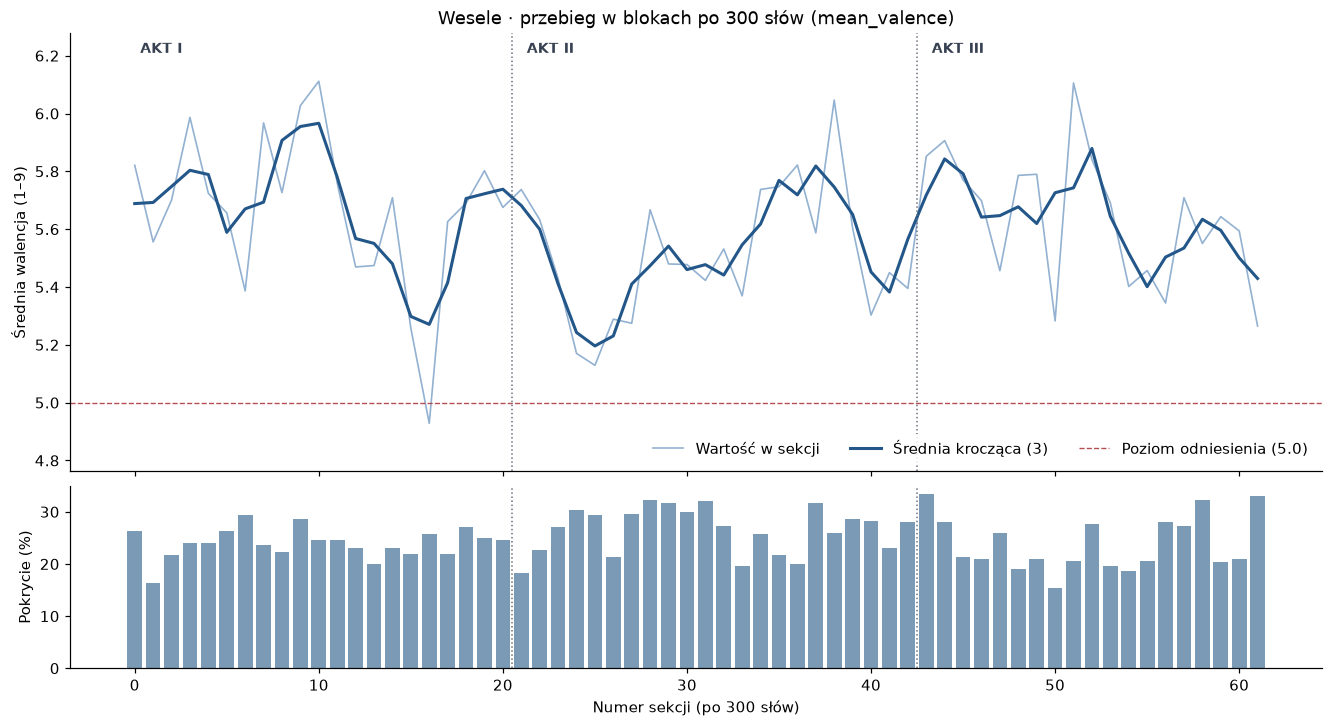

,total,matched,coverage_percent,mean_valence,net_per_1000
act,,,,,
AKT I,300.0,72.05,24.02,5.67,77.78
AKT II,300.0,79.73,26.58,5.51,64.09
AKT III,296.0,70.42,23.91,5.64,73.64


In [5]:
#@title 5. Wykres przebiegu sentymentu/walencji w trakcie „Wesela”
section_size = 300 #@param {type:"integer"}
metric = "mean_valence" #@param ["mean_valence", "net_per_1000"]
rolling_window = 3 #@param {type:"integer"}

if not 50 <= section_size <= 2000:
    raise ValueError("Wybierz section_size od 50 do 2000 słów.")

tokens_df["section"] = (tokens_df["position"] // section_size).astype(int)

trajectory = tokens_df.groupby("section", as_index=False).agg(
    total=("lemma", "size"),
    matched=("matched", "sum"),
    positive=("positive", "sum"),
    negative=("negative", "sum"),
    mean_valence=("valence", "mean"),
    act=("act", lambda s: s.mode().iloc[0]),
)
trajectory["net"] = trajectory["positive"] - trajectory["negative"]
trajectory["net_per_1000"] = 1000 * trajectory["net"] / trajectory["total"]
trajectory["coverage_percent"] = 100 * trajectory["matched"] / trajectory["total"]

# Exclude very short trailing fragments only from smoothed trend if desired, keep all on axis.
y_label = "Średnia walencja (1–9)" if metric == "mean_valence" else "Bilans na 1000 słów"
ref_value = 5.0 if metric == "mean_valence" else 0.0
smooth = trajectory[metric].rolling(window=max(1, rolling_window), center=True, min_periods=1).mean()

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.4, 1]}, layout="constrained"
)
ax_top.plot(trajectory["section"], trajectory[metric], color="#93b1d1", linewidth=1.1, label="Wartość w sekcji")
if rolling_window > 1:
    ax_top.plot(trajectory["section"], smooth, color="#235789", linewidth=2.0, label=f"Średnia krocząca ({rolling_window})")
ax_top.axhline(ref_value, color="#b54b53", linestyle="--", linewidth=0.9, label=f"Poziom odniesienia ({ref_value})")

# Mark boundaries between Acts I, II, III.
ax_top.margins(y=0.14)
act_changes = trajectory.loc[trajectory["act"] != trajectory["act"].shift(1), ["section", "act"]]
y_top = ax_top.get_ylim()[1]
for row in act_changes.itertuples():
    if row.section > 0:
        ax_top.axvline(row.section - 0.5, color="#6b7280", linestyle=":", linewidth=1.0)
        ax_bot.axvline(row.section - 0.5, color="#6b7280", linestyle=":", linewidth=1.0)
    ax_top.text(row.section + 0.3, y_top * 0.995, row.act, va="top", fontsize=9, color="#374151", fontweight="bold")

ax_top.set(title=f"Wesele · przebieg w blokach po {section_size} słów ({metric})", ylabel=y_label)
ax_top.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.85, edgecolor="none", ncol=3)

ax_bot.bar(trajectory["section"], trajectory["coverage_percent"], color="#6488a8", alpha=0.85, width=0.8)
ax_bot.set(ylabel="Pokrycie (%)", xlabel=f"Numer sekcji (po {section_size} słów)")
plt.show()

display(trajectory.groupby("act", sort=False)[["total", "matched", "coverage_percent", "mean_valence", "net_per_1000"]].mean().round(2))

In [6]:
#@title 6. Podgląd fragmentu i wkładu słów dla wybranej sekcji
section_number = -1 #@param {type:"integer"}

full_sections = trajectory.loc[trajectory["total"] == section_size]
if full_sections.empty:
    full_sections = trajectory

if section_number == -1:
    section_number = int(full_sections.loc[full_sections[metric].idxmin(), "section"])
elif section_number == -2:
    section_number = int(full_sections.loc[full_sections[metric].idxmax(), "section"])

selected_row = trajectory.loc[trajectory["section"] == section_number]
if selected_row.empty:
    raise ValueError(f"Wybierz numer sekcji od 0 do {int(trajectory['section'].max())}, albo -1 (min) / -2 (max).")

sec_tokens = tokens_df.loc[tokens_df["section"] == section_number]
print(f"Sekcja {section_number} · {selected_row['act'].iloc[0]}")
display(selected_row[["total", "matched", "coverage_percent", "mean_valence", "positive", "negative", "net_per_1000"]].round(2))

# Show words from the dictionary found in this section.
matched_words = (
    sec_tokens.loc[sec_tokens["matched"]]
    .groupby("lemma", as_index=False)
    .agg(
        count=("lemma", "size"),
        valence=("valence", "first"),
        arousal=("arousal", "first"),
        positive=("positive", "max"),
        negative=("negative", "max"),
        examples=("surface", lambda s: ", ".join(pd.unique(s)[:3])),
    )
    .sort_values(["valence", "count"], ascending=[True, False])
)
display(matched_words.rename(columns={
    "lemma": "Lemat", "count": "Liczba", "valence": "Walencja",
    "arousal": "Pobudzenie", "examples": "Formy w tekście",
}).round(2).head(15))

# Show original speeches overlapping this section.
speech_ids = sec_tokens["speech_id"].unique()
print("\n--- Oryginalny fragment dramatu ---")
for row in speeches_df.iloc[speech_ids].itertuples():
    print(f"[{row.scene}] {row.speaker}: {row.text}")

Sekcja 16 · AKT I


,total,matched,coverage_percent,mean_valence,positive,negative,net_per_1000
16,300,77,25.67,4.93,15,22,-23.33


,Lemat,Liczba,Walencja,Pobudzenie,positive,negative,Formy w tekście
1,bić,3,2.70,5.96,False,True,"biją, bije"
0,bieda,1,2.98,5.24,False,True,bieda
11,kat,1,3.06,5.94,False,True,kaci
7,dług,4,3.10,5.18,False,True,"Dług, dług"
12,kiepski,1,3.30,4.24,False,True,kiepskim
39,winny,1,3.34,5.16,False,True,winni
29,rozbić,1,3.80,4.68,False,True,rozbił
31,rząd,1,3.80,4.50,False,True,rządem
26,pusty,1,3.94,3.22,False,True,pustym
19,nie,8,4.00,4.68,False,True,"nie, Nie"



--- Oryginalny fragment dramatu ---
[SCENA XXVIII] ŻYD: Termin, ja to wim.
[SCENA XXVIII] KSIĄDZ: A Mosiek jest akuratny, to dlatego trzymam z nim.
[SCENA XXVIII] ŻYD: Co do czego Żyd jest nieprzydatny, to do takich rzeczy z groszem zawsze się przyda.
[SCENA XXVIII] KSIĄDZ: Po chłopach jednaka bieda; nic nie sprzedam z pustym koszem.
[SCENA XXVIII] ŻYD: Bierę, płacę.
[SCENA XXVIII] KSIĄDZ: Daję, bierę.
[SCENA XXVIII] ŻYD: Moje, twoje.
[SCENA XXVIII] KSIĄDZ: Twoje, moje. Chłopską biedą nie obstoję.
[SCENA XXVIII] ŻYD: Patrz dobrodzij, co się dzieje, przy stołach się chłopy biją! Czepiec Maćka gruchnoł w łeb.
[SCENA XXVIII] KSIĄDZ: Maciek ta ma mocną głowe.
[SCENA XXVIII] ŻYD: Może mu i nic nie zrobił, może rozbił na połowe.
[SCENA XXVIII] KSIĄDZ: A niech się ta chłopy biją. To Mosiek w nich wódkę leje, Żyd, chłop, wódka, stare dzieje.
[SCENA XXVIII] ŻYD: A sprzedaję, bo mam sklep; — Czepiec jutro ma mnie płacić, to dziś wkoło bije w pysk.
[SCENA XXVIII] KSIĄDZ: Na chłopach się chcesz b